# E04 · Coherence and what a camera averages

Connect interference, source bandwidth, source size, and speckle through one measurement: the time-averaged squared field.

<!-- course-preparation:start -->
## Before this lab

Use these focused refreshers if an idea is unfamiliar; you do not need to complete each linked course.

- **Complex amplitudes and phase:** Expand |u₁ + u₂|² and recognize complex-conjugate cross terms. Used here: The camera averages these interference terms during an exposure. [Review: MIT OCW · Complex Arithmetic and Exponentials](https://ocw.mit.edu/courses/18-03sc-differential-equations-fall-2011/pages/unit-i-first-order-differential-equations/complex-arithmetic-and-exponentials/). Read the notes on Euler's formula, polar form, multiplication, and complex conjugation. The differential-equation applications can wait.
- **Averages, variance, and correlation:** Distinguish averaging a product from multiplying averages, and independent from repeated samples. Used here: These distinctions govern fringe visibility and speckle contrast. [Review: MIT OCW · Probability readings, Classes 4, 6, and 7](https://ocw.mit.edu/courses/18-05-introduction-to-probability-and-statistics-spring-2022/pages/classes-reading-and-in-class-materials/). Read Class 4b on expectation, Class 6a on expectation and variance, and Class 7b on covariance and correlation. R exercises are not needed.

For the coherent-mode section and notebook extension, review eigenvectors and Hermitian matrices.
- [MIT OCW · Eigenvalues and Eigenvectors](https://ocw.mit.edu/courses/18-06sc-linear-algebra-fall-2011/pages/least-squares-determinants-and-eigenvalues/eigenvalues-and-eigenvectors/) — Start with the lecture summary and one 2 × 2 worked problem. Focus on Av = λv and what changes when a matrix is applied repeatedly.
- [MIT OCW · Lecture 26: Complex matrices; fast Fourier transform](https://ocw.mit.edu/courses/18-06-linear-algebra-spring-2010/resources/lecture-26-complex-matrices-fast-fourier-transform/) — Focus on complex vectors, conjugate transpose, Hermitian matrices, and unitary matrices. The FFT algorithm at the end is optional here.

**Python preparation:** Average arrays over a realization axis and compare standard deviation with mean intensity.
- [NumPy · The absolute basics for beginners](https://numpy.org/doc/stable/user/absolute_beginners.html) — Use the sections on array shape, indexing and slicing, basic operations, and broadcasting. Practice changing one parameter and rerunning a cell.

**Developed here:** Connect detector averaging to temporal coherence, spatial coherence, and speckle; then represent correlations with coherent modes.

[All prerequisites and learning resources](https://vandermode.github.io/optics-in-5-minutes-course/preparation/)
<!-- course-preparation:end -->

**Core lab: 25–30 minutes.** Work through the predictions before running the next cell. Sections labelled optional can be skipped on a first pass. Run all executes both the core and the small CPU extension.

**You will learn to:**

- Explain intensity addition as a consequence of averaged cross terms.
- Distinguish temporal coherence, spatial coherence, and fixed spatial randomness.
- Use mutual intensity and coherent modes to propagate partially coherent light.

**Model:** Stationary scalar, same-polarization fields; small-angle uniform angular source; Gaussian frequency spectrum. The product of temporal, spatial, and jitter correlations assumes separable independent effects. Speckle uses circular complex Gaussian fields filtered by a finite pupil.

This notebook is self-contained. It uses synthetic data, runs on CPU, and needs no repository clone, mounted Drive, API key, or external dataset. The setup installs only missing packages. Figures are displayed as static PNGs and also saved in a local folder for download.


In [1]:
import importlib.util, subprocess, sys
missing = [p for p in ["numpy", "scipy", "matplotlib"] if importlib.util.find_spec(p) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display, FileLink
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("png")
FIGURES = Path("e04_figures")
FIGURES.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.grid": False, "figure.constrained_layout.use": True})
def show(fig, name):
    fig.savefig(FIGURES / (name + ".png"), dpi=140, bbox_inches="tight")
    display(fig)
    plt.close(fig)
print("Python", sys.version.split()[0], "| NumPy", np.__version__, "| SciPy", scipy.__version__, "| Matplotlib", matplotlib.__version__)


Python 3.12.13 | NumPy 2.4.3 | SciPy 1.16.3 | Matplotlib 3.11.2


## 1 · Start with the detector average

Fields always superpose. Expanding the averaged squared sum gives
$I=I_1+I_2+2\operatorname{Re}\langle U_1U_2^*\rangle$.
Normalized correlation is $\gamma=\langle U_1U_2^*\rangle/\sqrt{I_1I_2}$.
Visibility equals $|\gamma|$ only for balanced beams with matching polarization.
**Predict:** can low visibility occur even when the relative phase is stable?

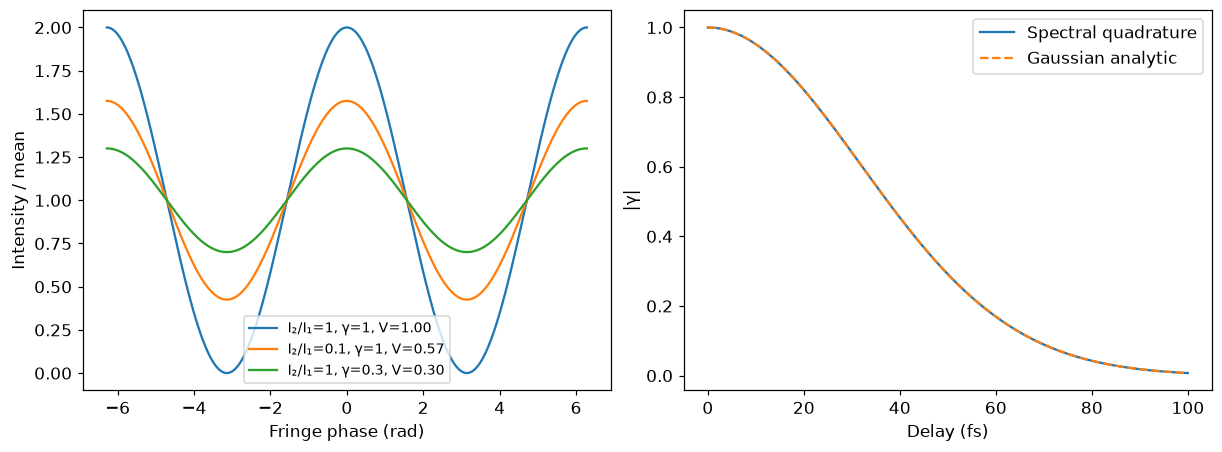

Gaussian spectrum Fourier-transform error: 3.6700841254955208e-09


In [2]:
phase=np.linspace(-2*np.pi,2*np.pi,501)
fig,ax=plt.subplots(1,2,figsize=(11,4))
for balance,gamma in [(1,1),(.1,1),(1,.3)]:
    I=1+balance+2*np.sqrt(balance)*gamma*np.cos(phase)
    V=2*np.sqrt(balance)*abs(gamma)/(1+balance)
    ax[0].plot(phase,I/(1+balance),label=f"I₂/I₁={balance}, γ={gamma}, V={V:.2f}")
ax[0].set(xlabel="Fringe phase (rad)",ylabel="Intensity / mean");ax[0].legend(fontsize=9)
sigma=5. # THz, baseband Gaussian spectrum
nu=np.linspace(-6*sigma,6*sigma,4001);weights=np.exp(-.5*(nu/sigma)**2);weights/=weights.sum()
tau=np.linspace(0,100,301) # fs
correlation=np.exp(-2j*np.pi*.001*tau[:,None]*nu)@weights
analytic=np.exp(-.5*(2*np.pi*.001*sigma*tau)**2)
assert np.max(abs(abs(correlation)-analytic))<5e-9
ax[1].plot(tau,abs(correlation),label="Spectral quadrature");ax[1].plot(tau,analytic,"--",label="Gaussian analytic")
ax[1].set(xlabel="Delay (fs)",ylabel="|γ|");ax[1].legend()
show(fig,"01-visibility-and-delay")
print("Gaussian spectrum Fourier-transform error:",np.max(abs(abs(correlation)-analytic)))

## 2 · Random across space does not mean changing in time

A fixed rough surface can produce a fixed random interference pattern. Averaging copies
of the same intensity leaves its contrast unchanged. Independent equal-weight patterns
approximately follow $C=\sigma_I/\langle I\rangle=1/\sqrt N$ for resolved,
fully developed single-polarization speckle. Finite images give sampling variation.

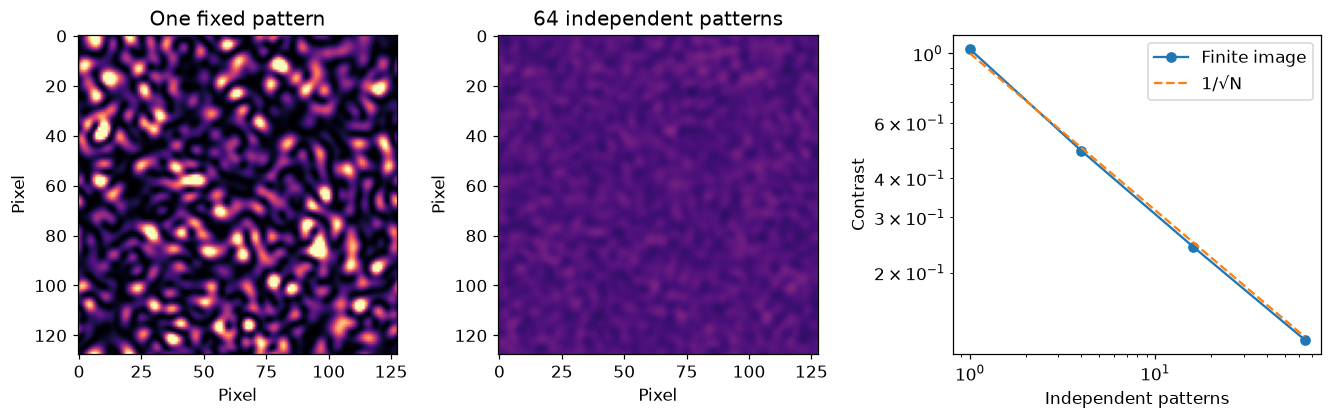

Measured contrasts: {np.int64(1): np.float64(1.0319437549450547), np.int64(4): np.float64(0.4890293492795309), np.int64(16): np.float64(0.2420299489605858), np.int64(64): np.float64(0.12228626837408525)}


In [3]:
rng=np.random.default_rng(17)
n=128;freq=np.fft.fftfreq(n)*n;FX,FY=np.meshgrid(freq,freq)
pupil=FX*FX+FY*FY<14**2
patterns=[]
for _ in range(64):
    field=np.fft.ifft2((rng.normal(size=(n,n))+1j*rng.normal(size=(n,n)))*pupil)
    I=abs(field)**2;patterns.append(I/I.mean())
patterns=np.asarray(patterns)
counts=np.array([1,4,16,64])
contrast=lambda image:image.std()/image.mean()
contrasts=np.array([contrast(patterns[:N].mean(axis=0)) for N in counts])
repeated=np.repeat(patterns[:1],64,axis=0).mean(axis=0)
assert abs(contrast(repeated)-contrast(patterns[0]))<1e-12
assert contrasts[-1]<.2 and contrasts[-1]<contrasts[0]/4
fig,ax=plt.subplots(1,3,figsize=(12,3.7))
for a,I,title in zip(ax[:2],[patterns[0],patterns.mean(axis=0)],["One fixed pattern","64 independent patterns"]):
    a.imshow(I,cmap="magma",vmin=0,vmax=4);a.set(title=title,xlabel="Pixel",ylabel="Pixel")
ax[2].loglog(counts,contrasts,"o-",label="Finite image");ax[2].loglog(counts,1/np.sqrt(counts),"--",label="1/√N")
ax[2].set(xlabel="Independent patterns",ylabel="Contrast");ax[2].legend()
show(fig,"02-speckle-averaging")
print("Measured contrasts:",dict(zip(counts,contrasts)))

## 3 · A matrix of correlations

$J_{ij}=\langle U_i U_j^*\rangle$ contains intensity on its diagonal and pairwise
complex correlations elsewhere. For two equal-intensity samples,
$J=[[1,\rho],[\rho,1]]$ has in-phase and out-of-phase modes with powers $1+\rho$ and $1-\rho$.
The general Hermitian positive-semidefinite matrix has the same decomposition.

Here each independent source angle produces a coherent field across the whole aperture.
The source weights add intensities between those fields; they do not remove interference within a field.

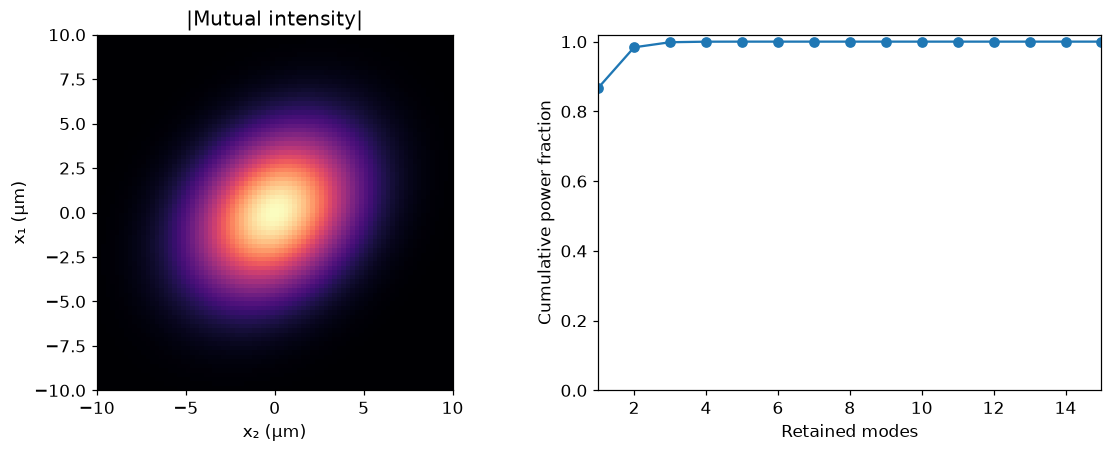

Trace / eigenvalue sum: 24.751699163959508 24.75169916395956


In [4]:
x=np.linspace(-10,10,80)
angles=np.linspace(-.04,.04,41)
weights=np.exp(-.5*(angles/.015)**2);weights/=weights.sum()
fields=np.exp(-(x[None,:]/5)**2)*np.exp(2j*np.pi/.55*angles[:,None]*x[None,:])
J=np.einsum("s,si,sj->ij",weights,fields,fields.conj())
powers,modes=np.linalg.eigh(J)
assert powers.min()>-1e-10
order=np.argsort(powers)[::-1];powers=np.maximum(powers[order],0);modes=modes[:,order]
assert np.linalg.norm(J-(modes*powers)@modes.conj().T)/np.linalg.norm(J)<1e-12
fig,ax=plt.subplots(1,2,figsize=(10,4))
ax[0].imshow(abs(J),origin="lower",extent=[x[0],x[-1],x[0],x[-1]],cmap="magma")
ax[0].set(xlabel="x₂ (μm)",ylabel="x₁ (μm)",title="|Mutual intensity|")
ax[1].plot(np.arange(1,len(powers)+1),np.cumsum(powers)/powers.sum(),"o-")
ax[1].set(xlim=(1,15),ylim=(0,1.02),xlabel="Retained modes",ylabel="Cumulative power fraction")
show(fig,"03-mutual-intensity")
print("Trace / eigenvalue sum:",np.trace(J).real,powers.sum())

## Optional extension · Propagate the correlations three ways

A linear field operator L sends J to $LJL^\dagger$. Equivalently, propagate each independent
source field, or each eigenmode, before summing weighted intensities. These complete
calculations must agree. A truncated mode sum is an approximation that needs its own error check.

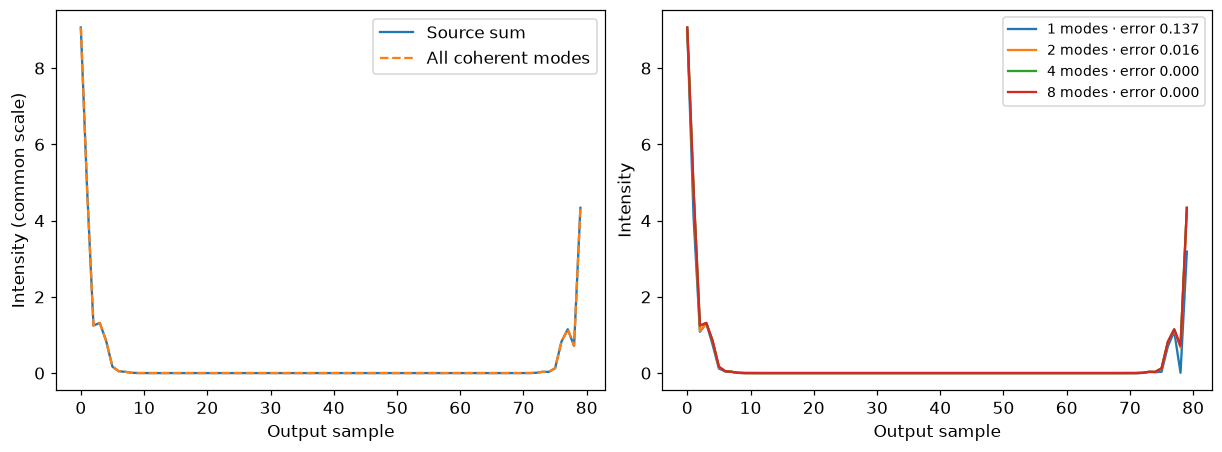

All-mode/source-sum maximum intensity difference: 7.105427357601002e-15


In [5]:
n=len(x)
phase_mask=np.exp(.7j*np.sin(x))
L=np.fft.fft(np.eye(n),axis=0,norm="ortho")@np.diag(phase_mask)
direct=np.sum(weights[:,None]*abs(fields@L.T)**2,axis=0)
matrix=np.diag(L@J@L.conj().T).real
propagated=L@modes
full=abs(propagated)**2@powers
assert np.max(abs(direct-matrix))<1e-12
assert np.max(abs(direct-full))<1e-12
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].plot(direct,label="Source sum");ax[0].plot(full,"--",label="All coherent modes")
ax[0].set(xlabel="Output sample",ylabel="Intensity (common scale)");ax[0].legend()
for K in [1,2,4,8]:
    approx=abs(propagated[:,:K])**2@powers[:K]
    error=np.linalg.norm(approx-direct)/np.linalg.norm(direct)
    ax[1].plot(approx,label=f"{K} modes · error {error:.3f}")
ax[1].set(xlabel="Output sample",ylabel="Intensity");ax[1].legend(fontsize=9)
show(fig,"04-mode-propagation")
print("All-mode/source-sum maximum intensity difference:",np.max(abs(full-direct)))

## A short lab report

**1. Diagnose low visibility.** Produce the same fringe visibility using intensity imbalance and phase averaging. Explain how to distinguish them.

**2. Audit the averaging law.** Compare fixed and independent realizations at N = 1, 4, 16, 64.

**3. Propagate correlations.** Compare direct source averaging with a full coherent-mode decomposition, then retain fewer modes.

### Worked reasoning

**Diagnose low visibility.** Measure each beam separately and check polarization before interpreting visibility as |γ|.

**Audit the averaging law.** Only independent equal-weight patterns give the ideal 1/√N scaling; finite fields give sampling variation.

**Propagate correlations.** The complete decompositions agree. Retained power and output intensity error should both be reported; a high retained-power fraction alone does not bound every pixel’s relative error.

### Ten-point rubric

Prediction and reasoning: 2; reproducible parameters, units, and plots: 3; quantitative validation: 3; limitations and interpretation: 2.

## References

- [MIT OpenCourseWare · Coherent and incoherent imaging](https://ocw.mit.edu/courses/2-71-optics-spring-2009/resources/lecture-22-coherent-and-incoherent-imaging/)
- [Singer & Vartanyants · Coherent-mode propagation](https://arxiv.org/abs/1108.6008)
- [Goodman · Statistical properties of laser speckle](https://opg.optica.org/josa/abstract.cfm?uri=josa-66-11-1145)

## Save your figures

The final cell creates a ZIP of the computed PNGs. In Colab, use the Files sidebar to download it if an output frame or link is blocked. Saved notebook outputs and the public lesson's figure download provide another viewing route.

In [6]:
import zipfile
archive = FIGURES.with_suffix(".zip")
with zipfile.ZipFile(archive, "w", zipfile.ZIP_DEFLATED) as bundle:
    for file in sorted(FIGURES.glob("*.png")):
        bundle.write(file, file.name)
print("Saved", len(list(FIGURES.glob("*.png"))), "figures in", archive)
display(FileLink(str(archive)))


Saved 4 figures in e04_figures.zip


/tmp/optics-notebooks-xppq4daw/E04/e04_figures.zip